# 00 - Chạy tuần tự toàn bộ pipeline (từng module)

Notebook này gọi lần lượt từng module trong `src/` theo đúng thứ tự của README để xem kết quả của từng bước.
Chạy từ trên xuống dưới (*Run All*) hoặc chạy từng mục riêng. Các cờ ở cell cấu hình bên dưới cho phép bỏ qua bước nặng.

| Mục | Module | Nội dung |
|---|---|---|
| 1 | `src/data_loader.py` | nạp dữ liệu, kiểm tra cấu trúc |
| 2 | `src/split.py` | chia 80/20 theo thời gian |
| 3 | `src/preprocess.py` | pipeline tiền xử lý, `MissingRateSelector` |
| 4 | `src/train.py` | huấn luyện, OOF, chọn ngưỡng (lr, rf, xgb) |
| 5 | `src/threshold.py` | ngưỡng đã chọn, so sánh các phương pháp |
| 6 | `src/models/*` | ablation, robustness (nặng, mặc định tắt) |
| 7 | `src/evaluate.py` | đánh giá 3 mức |
| 8 | `src/explain.py` | giải thích model |
| 9 | `src/failure_analysis.py` | mẫu bỏ sót, báo động giả |
| 10 | `app/dashboard.py` | demo Streamlit |

In [13]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

# ----- Cờ điều khiển -----
RETRAIN = False          # True: train lại cả 3 model dù đã có file .joblib (mặc định chỉ train model còn thiếu)
RUN_ABLATION = False     # True: chạy ablation (chậm, ghi đè results/ablation_<model>.json)
RUN_ROBUSTNESS = False   # True: chạy robustness theo khối thời gian (ghi results/robustness_<model>.json)
MODELS = config.MODEL_NAMES   # ["lr", "rf", "xgb"]
print("ROOT =", ROOT)

ROOT = c:\Users\ACER\Downloads\Industry_4_AI


## 1. `data_loader` - nạp và kiểm tra dữ liệu

In [14]:
from src import data_loader

data_loader.validate_structure()          # kỳ vọng Counter({590: 1567})
X, y, timestamps = data_loader.load_data()
print("X:", X.shape, "| y:", y.shape)
print("Nhãn (0=Pass, 1=Fail):", y.value_counts().to_dict())
print("Thời gian:", timestamps.min(), "->", timestamps.max())
X.iloc[:3, :8]

Counter({590: 1567})
X: (1567, 590) | y: (1567,)
Nhãn (0=Pass, 1=Fail): {0: 1463, 1: 104}
Thời gian: 2008-07-19 11:55:00 -> 2008-10-17 06:07:00


,0,1,2,3,4,5,6,7
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241


## 2. `split` - chia train/test theo thời gian

In [15]:
from src.split import time_split, stratified_split, describe_split

X_train, X_test, y_train, y_test = time_split(X, y, timestamps)
print("Chia theo thời gian (chính thức):")
describe_split(y_train, y_test)

print("\nChia stratified (chỉ để đối chiếu):")
_, _, ys_train, ys_test = stratified_split(X, y)
_ = describe_split(ys_train, ys_test)

Chia theo thời gian (chính thức):
       n_samples  n_fail  fail_rate
train       1253      87     0.0694
test         314      17     0.0541

Chia stratified (chỉ để đối chiếu):
       n_samples  n_fail  fail_rate
train       1253      83     0.0662
test         314      21     0.0669


## 3. `preprocess` - pipeline tiền xử lý (fit trên train)

In [16]:
from src.preprocess import MissingRateSelector, build_preprocessor

# 3a. MissingRateSelector: mask học từ train, áp lên test
sel = MissingRateSelector().fit(X_train)
print(f"Ngưỡng thiếu = {config.MISSING_THRESHOLD}: giữ {sel.get_support().sum()}/{len(sel.get_support())} cột")
print("transform train:", sel.transform(X_train).shape, "| transform test:", sel.transform(X_test).shape)

# 3b. Số cột sau từng bước của pipeline
prep = build_preprocessor().fit(X_train, y_train)
Z = X_train.copy()
rows = [("input", Z.shape[1])]
for name, step in prep.steps:
    Z = step.transform(Z)
    rows.append((name, Z.shape[1]))
pd.DataFrame(rows, columns=["sau bước", "số cột"])

Ngưỡng thiếu = 0.7: giữ 570/590 cột
transform train: (1253, 570) | transform test: (314, 570)


,sau bước,số cột
0,input,590
1,missing,570
2,impute,570
3,variance,448
4,scale,448
5,select,40


## 4. `train` - huấn luyện, OOF, chọn ngưỡng
Mỗi model ghi 4 file: `oof_proba`, `test_proba`, `threshold_<model>.json`, `saved_models/<model>.joblib`.
Mặc định chỉ train model chưa có file `.joblib` (đổi `RETRAIN = True` ở cell cấu hình để train lại).

In [17]:
from src import train

for name in MODELS:
    if RETRAIN or not config.model_path(name).exists():
        print(f"--- train {name} ---")
        train.train_model(name)
    else:
        print(f"[{name}] đã có {config.model_path(name).name}, bỏ qua (RETRAIN=False)")

[lr] đã có lr.joblib, bỏ qua (RETRAIN=False)
[rf] đã có rf.joblib, bỏ qua (RETRAIN=False)
[xgb] đã có xgb.joblib, bỏ qua (RETRAIN=False)


## 5. `threshold` - ngưỡng quyết định

In [18]:
from src.threshold import load_threshold, choose_threshold

oof = {m: np.load(config.oof_path(m)) for m in MODELS}
test_proba = {m: np.load(config.test_path(m)) for m in MODELS}

rows = []
for m in MODELS:
    rows.append({
        "model": m,
        "threshold đã lưu": load_threshold(m),
        "f1 (tính lại)": choose_threshold(y_train.to_numpy(), oof[m], method="f1"),
        "min_recall=0.7": choose_threshold(y_train.to_numpy(), oof[m], method="min_recall", min_recall=0.7),
        "budget 10%": choose_threshold(y_train.to_numpy(), oof[m], method="budget", max_flag_rate=0.10),
    })
pd.DataFrame(rows).set_index("model")

,threshold đã lưu,f1 (tính lại),min_recall=0.7,budget 10%
model,,,,
lr,0.60,0.60,0.40,0.76
rf,0.15,0.15,0.06,0.16
xgb,0.14,0.14,0.01,0.24


## 6. Ablation và robustness (nặng, mặc định tắt)
Đổi `RUN_ABLATION` / `RUN_ROBUSTNESS` ở cell cấu hình thành `True` để chạy.
Nếu để `False`, cell sẽ chỉ hiển thị kết quả đã lưu sẵn trong `results/`.

In [19]:
import json
from src.models import logistic, random_forest, xgboost_model

if RUN_ABLATION:
    for module in (logistic, random_forest, xgboost_model):
        print(f"--- ablation {module.__name__} ---")
        module.run_ablation()

if RUN_ROBUSTNESS:
    for m in MODELS:
        for k in range(1, config.N_TIME_BLOCKS):
            train.train_model(m, time_block=k)

for m in MODELS:
    p = config.ablation_path(m)
    if p.exists():
        print(f"\n=== ablation {m} ===")
        display(pd.DataFrame(json.loads(p.read_text(encoding='utf-8'))))
for m in MODELS:
    p = config.robustness_path(m)
    if p.exists():
        print(f"\n=== robustness {m} ===")
        display(pd.DataFrame(json.loads(p.read_text(encoding='utf-8'))))


=== ablation lr ===


,variant,threshold,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.60,0.178261,0.471264,0.258675,0.704284,0.159290
1,no_class_weight,0.08,0.155405,0.528736,0.240209,0.696654,0.142447
2,no_feature_selection,0.30,0.158416,0.367816,0.221453,0.621025,0.125449
3,threshold_0.5,0.50,0.157233,0.574713,0.246914,0.704284,0.159290



=== ablation rf ===


,variant,threshold,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.15,0.225564,0.344828,0.272727,0.722704,0.181936
1,no_class_weight,0.21,0.206897,0.275862,0.236453,0.708912,0.142898
2,no_feature_selection,0.10,0.184211,0.482759,0.266667,0.716996,0.195290
3,threshold_0.5,0.50,0.000000,0.000000,0.000000,0.722704,0.181936



=== ablation xgb ===


,variant,threshold,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.14,0.182796,0.390805,0.249084,0.701839,0.159250
1,no_scale_pos_weight,0.03,0.168000,0.482759,0.249258,0.704886,0.171676
2,no_feature_selection,0.09,0.252252,0.321839,0.282828,0.739092,0.191859
3,threshold_0.5,0.50,0.244444,0.126437,0.166667,0.701839,0.159250


## 7. `evaluate` - đánh giá 3 mức (model / system / industrial)

In [20]:
from src import evaluate

y_test_np = y_test.to_numpy()
model_rows, ci_rows = {}, []
for m in MODELS:
    thr = load_threshold(m)
    model_rows[m] = evaluate.model_level(y_test_np, test_proba[m], thr)
    for metric in evaluate.BOOTSTRAP_METRICS:
        lo, hi = evaluate.bootstrap_ci(y_test_np, test_proba[m], thr, metric, seed=config.SEED)
        ci_rows.append({"model": m, "metric": metric, "ci_low": lo, "ci_high": hi})

print("== Model level (tập test) ==")
display(pd.DataFrame(model_rows).T)
print("== Bootstrap 95% CI ==")
display(pd.DataFrame(ci_rows).pivot(index="model", columns="metric", values=["ci_low", "ci_high"]).round(3))

== Model level (tập test) ==


,threshold,precision,recall,f1,roc_auc,pr_auc,detection_rate,n_fail_total,n_fail_detected
lr,0.60,0.125000,0.294118,0.175439,0.647059,0.184127,0.294118,17.0,5.0
rf,0.15,0.090909,0.058824,0.071429,0.633888,0.085700,0.058824,17.0,1.0
xgb,0.14,0.078125,0.294118,0.123457,0.623292,0.096731,0.294118,17.0,5.0


== Bootstrap 95% CI ==


ci_low                          ci_high                         
metric     f1 precision recall roc_auc      f1 precision recall roc_auc
model                                                                  
lr      0.045     0.031  0.091   0.500   0.313     0.238  0.530   0.792
rf      0.000     0.000  0.000   0.511   0.222     0.333  0.200   0.762
xgb     0.027     0.016  0.077   0.485   0.225     0.153  0.545   0.750

In [21]:
print("== System level ==")
sys_rows = {m: evaluate.system_level(m) for m in MODELS}
display(pd.DataFrame({m: {k: v for k, v in r.items() if k != "robustness"} for m, r in sys_rows.items()}).T)

== System level ==


c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator VarianceThreshold from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimato

,model,status,threshold,n_flagged,false_alarm,latency_ms_mean,latency_ms_std,model_size_kb
lr,lr,ok,0.6,40,0.875,1.0155,0.345996,29.481445
rf,rf,ok,0.15,11,0.909091,31.423522,5.840422,4008.794922
xgb,xgb,ok,0.14,64,0.921875,2.654966,0.969009,422.614258


In [22]:
print("== Industrial level (tập test) ==")
for m in MODELS:
    il = evaluate.industrial_level(y_test_np, test_proba[m], load_threshold(m))
    print(f"\n[{m}] n_samples={il['n_samples']}, n_fail={il['n_fail']}")
    display(pd.DataFrame({k: il[k] for k in ["model", "khong_kiem_tra", "kiem_tra_ngau_nhien", "kiem_tra_100%"]}).T)
    display(evaluate.capture_at_k(y_test_np, test_proba[m], evaluate.CAPTURE_KS))

== Industrial level (tập test) ==

[lr] n_samples=314, n_fail=17


,flag_rate,ti_le_loi_chan_duoc,n_loi_chan_duoc,n_loi_lot_qua,canh_bao_tren_per_lo
model,0.127389,0.294118,5.000000,12.000000,127.388535
khong_kiem_tra,0.000000,0.000000,0.000000,17.000000,0.000000
kiem_tra_ngau_nhien,0.127389,0.127389,2.165605,14.834395,127.388535
kiem_tra_100%,1.000000,1.000000,17.000000,0.000000,1000.000000


,k,n_flagged,n_fail_captured,capture_rate
0,0.05,16,3,0.176471
1,0.10,31,4,0.235294
2,0.20,63,6,0.352941



[rf] n_samples=314, n_fail=17


,flag_rate,ti_le_loi_chan_duoc,n_loi_chan_duoc,n_loi_lot_qua,canh_bao_tren_per_lo
model,0.035032,0.058824,1.000000,16.000000,35.031847
khong_kiem_tra,0.000000,0.000000,0.000000,17.000000,0.000000
kiem_tra_ngau_nhien,0.035032,0.035032,0.595541,16.404459,35.031847
kiem_tra_100%,1.000000,1.000000,17.000000,0.000000,1000.000000


,k,n_flagged,n_fail_captured,capture_rate
0,0.05,16,1,0.058824
1,0.10,31,2,0.117647
2,0.20,63,6,0.352941



[xgb] n_samples=314, n_fail=17


,flag_rate,ti_le_loi_chan_duoc,n_loi_chan_duoc,n_loi_lot_qua,canh_bao_tren_per_lo
model,0.203822,0.294118,5.000000,12.000000,203.821656
khong_kiem_tra,0.000000,0.000000,0.000000,17.000000,0.000000
kiem_tra_ngau_nhien,0.203822,0.203822,3.464968,13.535032,203.821656
kiem_tra_100%,1.000000,1.000000,17.000000,0.000000,1000.000000


,k,n_flagged,n_fail_captured,capture_rate
0,0.05,16,1,0.058824
1,0.10,31,1,0.058824
2,0.20,63,5,0.294118


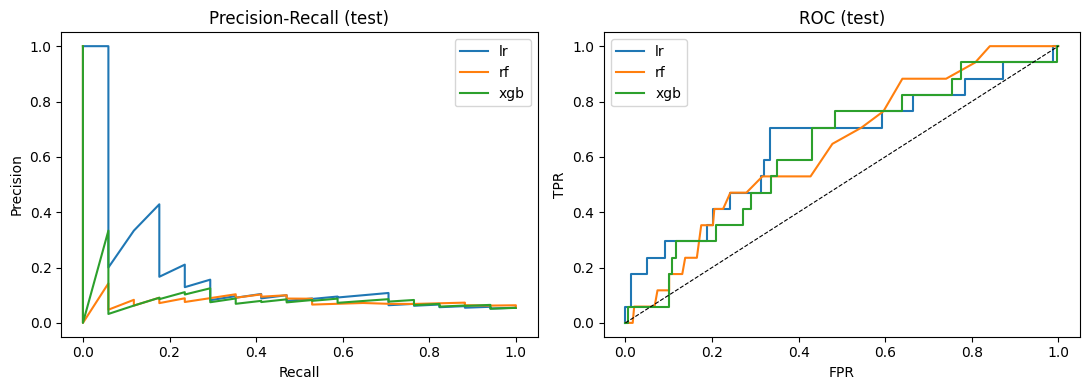

In [23]:
# Đường PR / ROC của 3 model trên test
from sklearn.metrics import precision_recall_curve, roc_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in MODELS:
    p, r, _ = precision_recall_curve(y_test_np, test_proba[m]); ax[0].plot(r, p, label=m)
    fpr, tpr, _ = roc_curve(y_test_np, test_proba[m]); ax[1].plot(fpr, tpr, label=m)
ax[0].set(title="Precision-Recall (test)", xlabel="Recall", ylabel="Precision"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set(title="ROC (test)", xlabel="FPR", ylabel="TPR"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. `explain` - giải thích model
Nhãn cột là **chỉ số cột gốc (0..589)**, truy ngược qua `get_support()` (kể cả `MissingRateSelector`).
Đây là mức đóng góp của sensor vào cảnh báo, không phải quan hệ nhân quả.

LR - 10 hệ số |lớn nhất|:


c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator VarianceThreshold from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimato

431    1.251938
59     0.904775
294   -0.891578
64     0.814385
436   -0.807598
348    0.679633
298    0.650922
159    0.631128
430    0.630738
21     0.581597
Name: coef, dtype: float64

RF - 10 importance lớn nhất:


59     0.107793
0      0.041383
33     0.041275
519    0.036520
64     0.034745
247    0.034688
79     0.033733
21     0.032980
129    0.032155
103    0.032030
Name: importance, dtype: float64

XGB - 10 sensor có mean|SHAP| lớn nhất (test):


59     0.842288
33     0.571700
21     0.354682
160    0.288430
122    0.286623
0      0.258207
65     0.241573
337    0.241368
22     0.231713
348    0.218004
dtype: float32

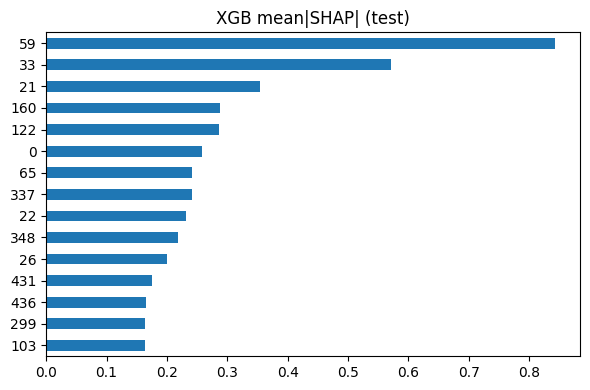

In [24]:
from src import explain

pipes = {m: joblib.load(config.model_path(m)) for m in MODELS}

coef = explain.lr_coefficients(pipes["lr"])
print("LR - 10 hệ số |lớn nhất|:")
display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10))

imp = explain.rf_importance(pipes["rf"])
print("RF - 10 importance lớn nhất:")
display(imp.sort_values(ascending=False).head(10))

shap_vals = explain.xgb_shap(pipes["xgb"], X_test)
mean_abs = shap_vals.abs().mean().sort_values(ascending=False)
print("XGB - 10 sensor có mean|SHAP| lớn nhất (test):")
display(mean_abs.head(10))
mean_abs.head(15).iloc[::-1].plot.barh(figsize=(6, 4), title="XGB mean|SHAP| (test)")
plt.tight_layout(); plt.show()

## 9. `failure_analysis` - khi nào model sai

In [25]:
from src import failure_analysis

cut = int(len(X) * (1 - config.TEST_SIZE))
ts_test = timestamps.iloc[cut:]
for m in MODELS:
    thr = load_threshold(m)
    missed = failure_analysis.missed_failures(y_test, test_proba[m], thr, ts_test)
    alarms = failure_analysis.false_alarms(y_test, test_proba[m], thr, ts_test)
    print(f"\n[{m}] threshold={thr:.2f} | Fail bị bỏ sót: {len(missed)}/{int(y_test.sum())} | báo động giả: {len(alarms)}")
    display(missed.head(5))


[lr] threshold=0.60 | Fail bị bỏ sót: 12/17 | báo động giả: 35


,sample_index,proba,timestamp
0,1302,0.237387,2008-10-04 23:18:00
1,1303,0.544258,2008-10-05 00:33:00
2,1324,0.150298,2008-10-05 15:30:00
3,1325,0.444801,2008-10-05 15:35:00
4,1328,0.537950,2008-10-05 16:49:00



[rf] threshold=0.15 | Fail bị bỏ sót: 16/17 | báo động giả: 10


,sample_index,proba,timestamp
0,1254,0.063333,2008-10-02 21:32:00
1,1302,0.026667,2008-10-04 23:18:00
2,1303,0.113333,2008-10-05 00:33:00
3,1324,0.036667,2008-10-05 15:30:00
4,1325,0.043333,2008-10-05 15:35:00



[xgb] threshold=0.14 | Fail bị bỏ sót: 12/17 | báo động giả: 59


,sample_index,proba,timestamp
0,1254,0.055563,2008-10-02 21:32:00
1,1302,0.007018,2008-10-04 23:18:00
2,1303,0.038216,2008-10-05 00:33:00
3,1324,0.007917,2008-10-05 15:30:00
4,1325,0.037498,2008-10-05 15:35:00


## 10. Dashboard (`app/dashboard.py`)
Streamlit chạy như một ứng dụng riêng, không chạy trong notebook. Mở terminal ở thư mục gốc repo và chạy:

```bash
streamlit run app/dashboard.py
```

In [26]:
# Kiểm tra nhanh các hàm lõi của dashboard (không cần mở giao diện)
import importlib.util
spec = importlib.util.spec_from_file_location("dashboard", ROOT / "app" / "dashboard.py")
dash = importlib.util.module_from_spec(spec); spec.loader.exec_module(dash)

pipe, thr = pipes["lr"], load_threshold("lr")
for i in range(3):
    risk = dash.predict_risk(pipe, X_test.iloc[[i]])
    print(f"Lô {i+1}: risk={risk:.3f}, ngưỡng={thr:.2f} -> {dash.recommend_action(risk, thr)}")

Lô 1: risk=0.651, ngưỡng=0.60 -> Giữ lô, kiểm tra thêm
Lô 2: risk=0.698, ngưỡng=0.60 -> Giữ lô, kiểm tra thêm
Lô 3: risk=0.522, ngưỡng=0.60 -> Cho qua, nhưng ghi nhận để theo dõi (risk gần ngưỡng)
